# HW7 Mini Project — Your IFR Interpolator

Design your own interpolator. For compatible data, it should be continuous, pass through the
supplied IFR points, and be **monotone and convex within the node interval**. Explain your choice
of method and how you handle data that cannot satisfy all these conditions.

You may consult **Hagan and West's method** for inspiration.

### Implement your subclass

Write your class in `fixedincomelib/utilities/numerics.py`, inheriting from `Interpolator1D`.
Implement `interpolate` and `integrate`; leave the two optional gradient stubs as supplied.
The `MONOTONE_CONVEX` entry in `InterpMethod` and its factory mapping to
`Interpolator1DMonotoneConvex` are supplied. The one-node funding curve must be constant.

Each cell gives the product terms explicitly and calls the existing library APIs directly.
Within each pair, change only `'interpolation method'` from
`'PIECEWISE_CONSTANT_LEFT_CONTINUOUS'` to `'MONOTONE_CONVEX'`; rebuilding the model selects
your class. Compare the PVs and briefly explain the differences. Use `FLAT` extrapolation
and the supplied IFR data; no calibration is needed.

Cell 1 includes the shared imports and data. Run cells **1, 3, 5** for the PCP results;
after completing your implementation, restart the kernel and run all six.



In [9]:
import pandas as pd
from fixedincomelib import (
    qfCreateData1D, qfCreateDataCollection,
    qfCreateBuildMethod, qfCreateModelBuildMethodCollection, qfCreateModel,
    qfCreateProductFRA, qfCreateProductRFRSwap, qfCreateProductOvernightIndexBasisSwap,
    qfCreateValuationParameters, qfCreateValuationParametersCollection,
    qfCreateValueReport,
)

# Supplied IFR point values, in annual decimals.
node_dates = ["2026-04-02", "2026-10-02", "2027-07-02",
              "2028-01-03", "2029-01-02", "2031-01-02"]
sofr_quotes = pd.DataFrame({"values": [0.025, 0.026, 0.028, 0.030, 0.035, 0.047]}, index=node_dates)
ff_quotes = pd.DataFrame({"values": [0.023, 0.0237, 0.0252, 0.0265, 0.0305, 0.0405]}, index=node_dates)
funding_quotes = pd.DataFrame({"values": [0.0005]}, index=["2027-01-04"])
data_collection = qfCreateDataCollection([
    qfCreateData1D("INSTANTANEOUS FORWARD RATE", "SOFR-1B-IFR", sofr_quotes),
    qfCreateData1D("INSTANTANEOUS FORWARD RATE", "FF-1B-IFR", ff_quotes),
    qfCreateData1D("INSTANTANEOUS FORWARD RATE", "SOFR-1B-FUNDING-IFR", funding_quotes),
])
curve_inputs = [
    ("YIELD_CURVE_INDEX", {"TARGET": "SOFR-1B", "INSTANTANEOUS FORWARD RATE": "SOFR-1B-IFR"}),
    ("YIELD_CURVE_INDEX", {"TARGET": "FF-1B", "INSTANTANEOUS FORWARD RATE": "FF-1B-IFR"}),
    ("YIELD_CURVE_FUNDING", {"TARGET": "SOFR-1B-FLAT", "REFERENCE INDEX": "SOFR-1B",
                            "INSTANTANEOUS FORWARD RATE": "SOFR-1B-FUNDING-IFR"}),
]


### Include an IFR curve plot and briefly explain how your method ensures monotonicity and convexity.

SOFR-1B: max node error 0.0e+00 | monotone: True | convex: True
FF-1B: max node error 0.0e+00 | monotone: True | convex: True


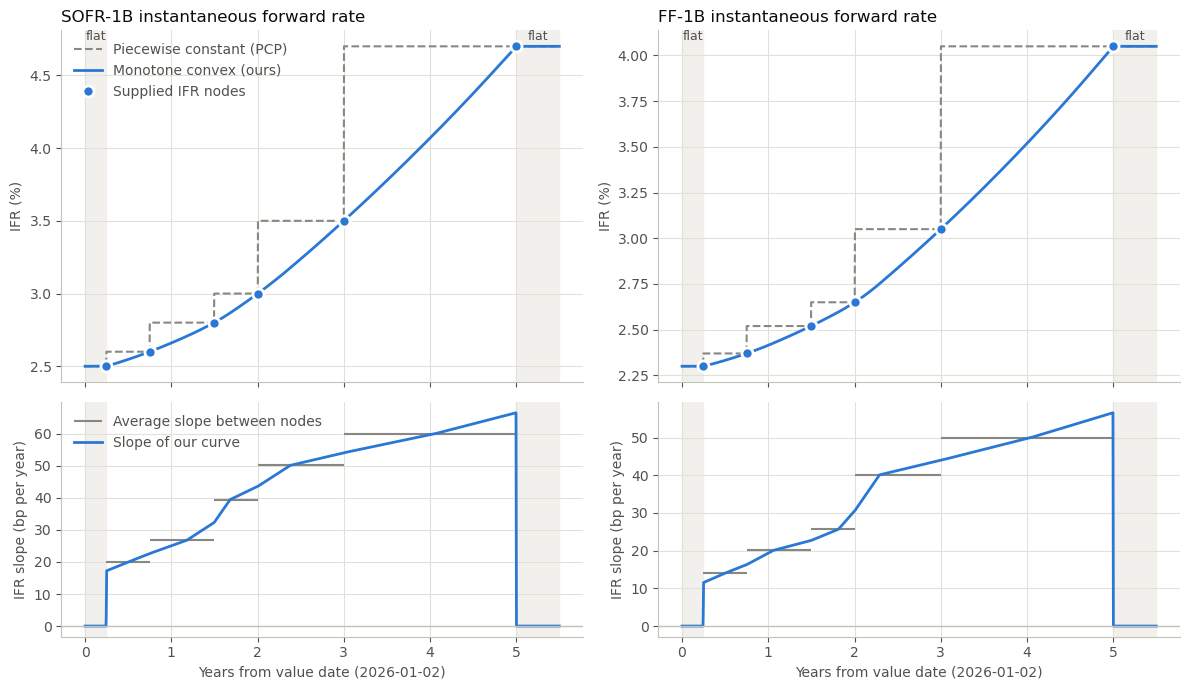

In [10]:
import numpy as np
import matplotlib.pyplot as plt

# Build both curve sets through the library, so the plot shows exactly what gets priced.
def build_components(interp_method):
    methods = qfCreateModelBuildMethodCollection([
        qfCreateBuildMethod(kind, {**inputs,
                                   "INTERPOLATION METHOD": interp_method,
                                   "EXTRAPOLATION METHOD": "FLAT"})
        for kind, inputs in curve_inputs
    ])
    model = qfCreateModel("2026-01-02", "YIELD_CURVE", data_collection, methods)
    return {name: model.retrieve_model_component(name) for name in ("SOFR-1B", "FF-1B")}

mc_curves = build_components("MONOTONE_CONVEX")
pcp_curves = build_components("PIECEWISE_CONSTANT_LEFT_CONTINUOUS")

BLUE, GRAY = "#2a78d6", "#898781"            # our curve; piecewise-constant reference
INK, GRID, EXTRAP = "#52514e", "#e1e0d9", "#f1f0ec"
grid = np.linspace(0.0, 5.5, 2201)

fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True, gridspec_kw={"height_ratios": [3, 2]})
for col, name in enumerate(("SOFR-1B", "FF-1B")):
    mc = mc_curves[name].state_data_interpolator
    pcp = pcp_curves[name].state_data_interpolator
    t, f = mc_curves[name].state_data
    y_mc = np.array([mc.interpolate(x) for x in grid])
    y_pcp = np.array([pcp.interpolate(x) for x in grid])
    slope = np.gradient(y_mc, grid)
    secants = np.diff(f) / np.diff(t)

    top, bottom = axes[0, col], axes[1, col]
    for ax in (top, bottom):
        ax.axvspan(grid[0], t[0], color=EXTRAP, zorder=0)
        ax.axvspan(t[-1], grid[-1], color=EXTRAP, zorder=0)
        ax.grid(color=GRID, linewidth=0.8)
        ax.set_axisbelow(True)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
        ax.spines[["left", "bottom"]].set_color("#c3c2b7")
        ax.tick_params(colors=INK)

    # Top: IFR level
    top.plot(grid, 100 * y_pcp, color=GRAY, linewidth=1.5, linestyle="--", label="Piecewise constant (PCP)")
    top.plot(grid, 100 * y_mc, color=BLUE, linewidth=2, label="Monotone convex (ours)")
    top.plot(t, 100 * f, "o", color=BLUE, markersize=8, markeredgecolor="white",
             markeredgewidth=2, label="Supplied IFR nodes", zorder=3)
    top.set_title(f"{name} instantaneous forward rate", color="#0b0b0b", loc="left")
    top.set_ylabel("IFR (%)", color=INK)
    top.text(t[0] / 2, top.get_ylim()[1], "flat", ha="center", va="top", color=INK, fontsize=9)
    top.text((t[-1] + grid[-1]) / 2, top.get_ylim()[1], "flat", ha="center", va="top", color=INK, fontsize=9)

    # Bottom: slope of the IFR, against the average slope between nodes
    bottom.hlines(1e4 * secants, t[:-1], t[1:], color=GRAY, linewidth=1.5,
                  label="Average slope between nodes")
    bottom.plot(grid, 1e4 * slope, color=BLUE, linewidth=2, label="Slope of our curve")
    bottom.axhline(0, color="#c3c2b7", linewidth=1)
    bottom.set_ylabel("IFR slope (bp per year)", color=INK)
    bottom.set_xlabel("Years from value date (2026-01-02)", color=INK)

    # Numerical check on the node range [t_1, t_n], using the slope over each small grid step
    xs = np.linspace(t[0], t[-1], 4001)
    steps = np.diff([mc.interpolate(x) for x in xs]) / np.diff(xs)
    node_err = max(abs(mc.interpolate(x) - v) for x, v in zip(t, f))
    print(f"{name}: max node error {node_err:.1e} | monotone: {steps.min() >= 0} "
          f"| convex: {np.all(np.diff(steps) >= -1e-12)}")

axes[0, 0].legend(frameon=False, loc="upper left", labelcolor=INK)
axes[1, 0].legend(frameon=False, loc="upper left", labelcolor=INK)
fig.tight_layout()
plt.show()


### The method

I used a **shape-preserving quadratic spline**, where, between each pair of nodes, the curve is made of two quadratic pieces that join smoothly in the middle.

**Choice of method**
- It passes through every IFR point and has no jumps.
- It doesn't overshoot between nodes the way a regular cubic spline can (Hagan and West show this in Figures 2–4).
- Each piece only depends on nearby nodes, so changing one input only changes the curve nearby.
- We couldn't use Hagan and West's method directly, because it works with *average* forward rates over each interval, while we're given the IFR at specific points. I borrowed a few of its ideas instead (see below).

**How it works**
1. **Slope at each node.** Each node's slope is a weighted average of the slopes of the lines to its two neighbours, so it always sits between them. If a node is a peak or a trough, its slope is set to 0. Each slope is also capped at 2× the smaller neighbouring slope. (The zero-slope rule and the cap are ideas from Hagan and West.)
2. **Shape between nodes.** Between two nodes, the curve's slope changes in a straight line: from the left node's slope, to the interval's average slope at a middle point, then to the right node's slope. I place that middle point so the curve lands exactly on the next node.
3. **Outside the nodes.** The curve is flat before the first node and after the last one. The funding curve only has one node, so it's a constant.

**Why it's monotone and convex.** For both SOFR and FF, the rates go up and the slope between nodes gets steeper each time (for SOFR: 20, 27, 40, 50, 60 bp per year). Since each node's slope sits between its neighbours', the curve's slope only ever increases, which makes the curve convex. All the slopes are positive, so the curve is also increasing. The bottom panels of the plot show this: the blue slope line keeps rising and crosses each grey "average slope" line once. The printed check confirms it on a fine grid.

**When the data doesn't allow everything.** If I can't satisfy every condition, I keep them in this order: pass through the points, no jumps, monotone, convex, smooth.
- **Peak or trough:** the slope there is 0, so the curve doesn't overshoot the data.
- **Data that bends downward:** the curve bends downward too, following the data.
- **Data that switches its bend between two nodes:** a smooth curve can't be convex there, so that piece becomes S-shaped. The slope cap keeps it monotone.
- **Three points exactly on a line, then a bend:** the curve has no jumps and stays convex, but gets a small corner at one node.


In [11]:
# 1. FRA — piecewise constant
fra_pcp_convention = {
    'effective date': '2026-05-05',
    'termination date': '2026-11-05',
    'projection index': 'SOFR-1B',
    'fixed rate': 0.032,
    'notional': 1000000,
    'pay or receive': 'receive',
    'accrual basis': 'ACT/360',
    'business day convention': 'F',
    'holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'PIECEWISE_CONSTANT_LEFT_CONTINUOUS',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": fra_pcp_convention["interpolation method"],
        "EXTRAPOLATION METHOD": fra_pcp_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
fra_pcp_model = qfCreateModel(
    fra_pcp_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
fra_pcp_product = qfCreateProductFRA(
    effective_date=fra_pcp_convention['effective date'],
    term_or_termination_date=fra_pcp_convention['termination date'],
    projection_index=fra_pcp_convention['projection index'],
    fixed_rate=fra_pcp_convention['fixed rate'],
    notional=fra_pcp_convention['notional'],
    pay_or_rec=fra_pcp_convention['pay or receive'],
    accrual_basis=fra_pcp_convention['accrual basis'],
    business_day_convention=fra_pcp_convention['business day convention'],
    holiday_convention=fra_pcp_convention['holiday convention'],
)
fra_pcp_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": fra_pcp_convention["funding index"],
    }),
])
fra_pcp_pv = qfCreateValueReport(fra_pcp_model, fra_pcp_product, fra_pcp_parameters, "PV")[0][1]
print("FRA | PCP PV:", fra_pcp_pv)


FRA | PCP PV: 2908.2866392379638


In [12]:
# 2. FRA — your interpolator
fra_student_convention = {
    'effective date': '2026-05-05',
    'termination date': '2026-11-05',
    'projection index': 'SOFR-1B',
    'fixed rate': 0.032,
    'notional': 1000000,
    'pay or receive': 'receive',
    'accrual basis': 'ACT/360',
    'business day convention': 'F',
    'holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'MONOTONE_CONVEX',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": fra_student_convention["interpolation method"],
        "EXTRAPOLATION METHOD": fra_student_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
fra_student_model = qfCreateModel(
    fra_student_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
fra_student_product = qfCreateProductFRA(
    effective_date=fra_student_convention['effective date'],
    term_or_termination_date=fra_student_convention['termination date'],
    projection_index=fra_student_convention['projection index'],
    fixed_rate=fra_student_convention['fixed rate'],
    notional=fra_student_convention['notional'],
    pay_or_rec=fra_student_convention['pay or receive'],
    accrual_basis=fra_student_convention['accrual basis'],
    business_day_convention=fra_student_convention['business day convention'],
    holiday_convention=fra_student_convention['holiday convention'],
)
fra_student_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": fra_student_convention["funding index"],
    }),
])
fra_student_pv = qfCreateValueReport(fra_student_model, fra_student_product, fra_student_parameters, "PV")[0][1]
print("FRA | Student PV:", fra_student_pv)
print("Student minus PCP:", fra_student_pv - fra_pcp_pv)


FRA | Student PV: 3261.6326017817046
Student minus PCP: 353.3459625437408


In [13]:
# 3. RFR swap — piecewise constant
swap_pcp_convention = {
    'effective date': '2026-04-02',
    'termination date': '2029-04-02',
    'overnight index': 'SOFR-1B',
    'fixed rate': 0.034,
    'notional': 1000000,
    'pay or receive': 'receive',
    'fixed accrual period': '1Y',
    'floating accrual period': '1Y',
    'accrual basis': 'ACT/360',
    'compounding method': 'compound',
    'floating spread': 0.0,
    'payment offset': '2D',
    'payment business day convention': 'F',
    'payment holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'PIECEWISE_CONSTANT_LEFT_CONTINUOUS',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": swap_pcp_convention["interpolation method"],
        "EXTRAPOLATION METHOD": swap_pcp_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
swap_pcp_model = qfCreateModel(
    swap_pcp_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
swap_pcp_product = qfCreateProductRFRSwap(
    effective_date=swap_pcp_convention['effective date'],
    term_or_termination_date=swap_pcp_convention['termination date'],
    on_index=swap_pcp_convention['overnight index'],
    fixed_rate=swap_pcp_convention['fixed rate'],
    notional=swap_pcp_convention['notional'],
    pay_or_rec=swap_pcp_convention['pay or receive'],
    accrual_period=swap_pcp_convention['fixed accrual period'],
    floating_leg_accrual_period=swap_pcp_convention['floating accrual period'],
    accrual_basis=swap_pcp_convention['accrual basis'],
    compounding_method=swap_pcp_convention['compounding method'],
    spread=swap_pcp_convention['floating spread'],
    payment_off_set=swap_pcp_convention['payment offset'],
    pay_business_day_convention=swap_pcp_convention['payment business day convention'],
    pay_holiday_convention=swap_pcp_convention['payment holiday convention'],
)
swap_pcp_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": swap_pcp_convention["funding index"],
    }),
])
swap_pcp_pv = qfCreateValueReport(swap_pcp_model, swap_pcp_product, swap_pcp_parameters, "PV")[0][1]
print("RFR swap | PCP PV:", swap_pcp_pv)


RFR swap | PCP PV: 6222.517513070154


In [14]:
# 4. RFR swap — your interpolator
swap_student_convention = {
    'effective date': '2026-04-02',
    'termination date': '2029-04-02',
    'overnight index': 'SOFR-1B',
    'fixed rate': 0.034,
    'notional': 1000000,
    'pay or receive': 'receive',
    'fixed accrual period': '1Y',
    'floating accrual period': '1Y',
    'accrual basis': 'ACT/360',
    'compounding method': 'compound',
    'floating spread': 0.0,
    'payment offset': '2D',
    'payment business day convention': 'F',
    'payment holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'MONOTONE_CONVEX',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": swap_student_convention["interpolation method"],
        "EXTRAPOLATION METHOD": swap_student_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
swap_student_model = qfCreateModel(
    swap_student_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
swap_student_product = qfCreateProductRFRSwap(
    effective_date=swap_student_convention['effective date'],
    term_or_termination_date=swap_student_convention['termination date'],
    on_index=swap_student_convention['overnight index'],
    fixed_rate=swap_student_convention['fixed rate'],
    notional=swap_student_convention['notional'],
    pay_or_rec=swap_student_convention['pay or receive'],
    accrual_period=swap_student_convention['fixed accrual period'],
    floating_leg_accrual_period=swap_student_convention['floating accrual period'],
    accrual_basis=swap_student_convention['accrual basis'],
    compounding_method=swap_student_convention['compounding method'],
    spread=swap_student_convention['floating spread'],
    payment_off_set=swap_student_convention['payment offset'],
    pay_business_day_convention=swap_student_convention['payment business day convention'],
    pay_holiday_convention=swap_student_convention['payment holiday convention'],
)
swap_student_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": swap_student_convention["funding index"],
    }),
])
swap_student_pv = qfCreateValueReport(swap_student_model, swap_student_product, swap_student_parameters, "PV")[0][1]
print("RFR swap | Student PV:", swap_student_pv)
print("Student minus PCP:", swap_student_pv - swap_pcp_pv)


RFR swap | Student PV: 12848.060546480847
Student minus PCP: 6625.543033410693


In [15]:
# 5. Overnight basis swap — piecewise constant
basis_pcp_convention = {
    'effective date': '2026-07-02',
    'termination date': '2028-07-03',
    'overnight index leg 1': 'SOFR-1B',
    'overnight index leg 2': 'FF-1B',
    'spread over leg 1': 0.001,
    'notional': 1000000,
    'pay or receive leg 1': 'receive',
    'accrual period leg 1': '3M',
    'accrual period leg 2': '3M',
    'accrual basis': 'ACT/360',
    'compounding method': 'compound',
    'payment offset': '2D',
    'payment business day convention': 'F',
    'payment holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'PIECEWISE_CONSTANT_LEFT_CONTINUOUS',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": basis_pcp_convention["interpolation method"],
        "EXTRAPOLATION METHOD": basis_pcp_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
basis_pcp_model = qfCreateModel(
    basis_pcp_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
basis_pcp_product = qfCreateProductOvernightIndexBasisSwap(
    effective_date=basis_pcp_convention['effective date'],
    term_or_termination_date=basis_pcp_convention['termination date'],
    on_index_leg_1=basis_pcp_convention['overnight index leg 1'],
    on_index_leg_2=basis_pcp_convention['overnight index leg 2'],
    spread_over_leg_1=basis_pcp_convention['spread over leg 1'],
    notional=basis_pcp_convention['notional'],
    pay_or_rec_leg_1=basis_pcp_convention['pay or receive leg 1'],
    accrual_period_1=basis_pcp_convention['accrual period leg 1'],
    accrual_period_2=basis_pcp_convention['accrual period leg 2'],
    accrual_basis=basis_pcp_convention['accrual basis'],
    compounding_method=basis_pcp_convention['compounding method'],
    payment_off_set=basis_pcp_convention['payment offset'],
    pay_business_day_convention=basis_pcp_convention['payment business day convention'],
    pay_holiday_convention=basis_pcp_convention['payment holiday convention'],
)
basis_pcp_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": basis_pcp_convention["funding index"],
    }),
])
basis_pcp_pv = qfCreateValueReport(basis_pcp_model, basis_pcp_product, basis_pcp_parameters, "PV")[0][1]
print("Overnight basis swap | PCP PV:", basis_pcp_pv)


Overnight basis swap | PCP PV: 8351.348908181993


In [16]:
# 6. Overnight basis swap — your interpolator
basis_student_convention = {
    'effective date': '2026-07-02',
    'termination date': '2028-07-03',
    'overnight index leg 1': 'SOFR-1B',
    'overnight index leg 2': 'FF-1B',
    'spread over leg 1': 0.001,
    'notional': 1000000,
    'pay or receive leg 1': 'receive',
    'accrual period leg 1': '3M',
    'accrual period leg 2': '3M',
    'accrual basis': 'ACT/360',
    'compounding method': 'compound',
    'payment offset': '2D',
    'payment business day convention': 'F',
    'payment holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'MONOTONE_CONVEX',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": basis_student_convention["interpolation method"],
        "EXTRAPOLATION METHOD": basis_student_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
basis_student_model = qfCreateModel(
    basis_student_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
basis_student_product = qfCreateProductOvernightIndexBasisSwap(
    effective_date=basis_student_convention['effective date'],
    term_or_termination_date=basis_student_convention['termination date'],
    on_index_leg_1=basis_student_convention['overnight index leg 1'],
    on_index_leg_2=basis_student_convention['overnight index leg 2'],
    spread_over_leg_1=basis_student_convention['spread over leg 1'],
    notional=basis_student_convention['notional'],
    pay_or_rec_leg_1=basis_student_convention['pay or receive leg 1'],
    accrual_period_1=basis_student_convention['accrual period leg 1'],
    accrual_period_2=basis_student_convention['accrual period leg 2'],
    accrual_basis=basis_student_convention['accrual basis'],
    compounding_method=basis_student_convention['compounding method'],
    payment_off_set=basis_student_convention['payment offset'],
    pay_business_day_convention=basis_student_convention['payment business day convention'],
    pay_holiday_convention=basis_student_convention['payment holiday convention'],
)
basis_student_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": basis_student_convention["funding index"],
    }),
])
basis_student_pv = qfCreateValueReport(basis_student_model, basis_student_product, basis_student_parameters, "PV")[0][1]
print("Overnight basis swap | Student PV:", basis_student_pv)
print("Student minus PCP:", basis_student_pv - basis_pcp_pv)


Overnight basis swap | Student PV: 7625.854675356146
Student minus PCP: -725.4942328258476


### Comparing the PVs

| Product | PCP PV | My PV | Difference |
|---|---|---|---|
| FRA (receive fixed 3.2%) | 2,908.29 | 3,261.63 | +353.35 |
| RFR swap (receive fixed 3.4%) | 6,222.52 | 12,848.06 | +6,625.54 |
| Basis swap (receive SOFR + 10 bp, pay FF) | 8,351.35 | 7,625.85 | −725.49 |

The funding curve is a flat 0.05% under both methods, so discounting is the same and all the differences come from the forward rates. PCP uses the *next* node's value for the whole interval before it, so on these rising curves it's always at least as high as my curve, which rises smoothly between nodes. That makes my forwards lower.

- **FRA (+353):** I receive a fixed 3.2% and pay SOFR. Over the FRA period my SOFR forwards are 7 bp lower on average, so I pay less: 7 bp × 0.51 years × \$1m ≈ \$360.
- **RFR swap (+6,626):** Same idea over three years, with SOFR 23 bp lower on average. The biggest gap is Jan–Apr 2029, where PCP has already jumped to 4.7% but my curve is only around 3.5–3.65%.
- **Basis swap (−725):** I receive SOFR + 10 bp and pay FF. Both fall, but SOFR falls 16.5 bp and FF only 12.6 bp, so I lose about 3.9 bp more on the leg I receive than I save on the leg I pay: 3.9 bp × 2 years × \$1m ≈ \$780.
